# RESPIRA — Unsupervised Learning: K-Means Spatial Risk Clustering
## Pemodelan Klaster Spasial Risiko Kualitas Udara & Kerentanan ISPA DKI Jakarta

**Pilar Machine Learning #3: Unsupervised Pattern Discovery**

### 1. Latar Belakang & Problem Statement
Distribusi polusi udara dan insidensi ISPA di DKI Jakarta memiliki karakteristik spasial yang sangat heterogen. Kawasan industri dan koridor lintas logistik (Jakarta Barat dan Jakarta Timur) menghadapi karakteristik partikel tersuspensi pekat, sementara kawasan pesisir (Jakarta Utara dan Kepulauan Seribu) memiliki dispersi angin laut yang dinamis. 

Untuk melengkapi model regresi beban kasus dan klasifikasi ISPU, model ini menerapkan **K-Means Clustering** untuk mengidentifikasi kelompok risiko lingkungan secara objektif tanpa label apriori (*unsupervised*).

### 2. Formulasi Matematis K-Means
Tujuan optimasi K-Means adalah meminimalkan *Within-Cluster Sum of Squares* (WCSS) atau inersia:
$$J = \sum_{k=1}^K \sum_{x \in C_k} ||x - \mu_k||^2$$

Di mana:
- $K$ adalah jumlah klaster optimal (dievaluasi melalui *Elbow Method* dan *Silhouette Analysis*).
- $C_k$ adalah himpunan titik observasi dalam klaster ke-$k$.
- $\mu_k$ adalah vektor pusat massa (*Centroid*) klaster ke-$k$:
$$\mu_k = \frac{1}{|C_k|} \sum_{x \in C_k} x$$

Setiap titik observasi baru $x'$ dialokasikan ke klaster $k^*$ dengan jarak Euclidean terpendek:
$$k^* = \arg\min_k ||x' - \mu_k||_2$$


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import joblib

# Set visual theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("✓ Modul Machine Learning K-Means siap!")


✓ Modul Machine Learning K-Means siap!


### 3. Eksplorasi Data Pemantauan SPKU DLH DKI Jakarta
Dataset memuat 1.796 baris data pengukuran riil dari stasiun pemantau kualitas udara (SPKU) Dinas Lingkungan Hidup DKI Jakarta dengan 6 parameter polutan:
- `pm25`: Particulate Matter $\le 2.5\,\mu\text{m}$ ($\mu\text{g}/\text{m}^3$)
- `pm10`: Particulate Matter $\le 10\,\mu\text{m}$ ($\mu\text{g}/\text{m}^3$)
- `so2`: Sulfur Dioksida ($\mu\text{g}/\text{m}^3$)
- `co`: Karbon Monoksida ($\text{mg}/\text{m}^3$)
- `o3`: Ozon Permukaan ($\mu\text{g}/\text{m}^3$)
- `no2`: Nitrogen Dioksida ($\mu\text{g}/\text{m}^3$)


In [2]:
data_path = "data/cleaned_ispu_dataset.csv"
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Dataset tidak ditemukan di {data_path}")

df = pd.read_csv(data_path)
features = ['pm25', 'pm10', 'so2', 'co', 'o3', 'no2']
X_raw = df[features]

print(f"Total Sampel Data Riil : {len(df):,} observasi")
print(f"Fitur Multi-Polutan    : {features}")
print("\nStatistik Deskriptif Fitur:")
display_stats = X_raw.describe().round(2)
print(display_stats)


Total Sampel Data Riil : 1,796 observasi
Fitur Multi-Polutan    : ['pm25', 'pm10', 'so2', 'co', 'o3', 'no2']

Statistik Deskriptif Fitur:
          pm25     pm10      so2       co       o3      no2
count  1796.00  1796.00  1796.00  1796.00  1796.00  1796.00
mean     83.10    55.47    38.51    13.08    37.35    21.92
std      23.83    13.63    12.19     5.85    19.71     9.43
min      13.00    15.00     2.00     3.00     9.00     1.00
25%      68.00    49.00    28.00     9.00    24.00    15.00
50%      82.00    56.00    40.00    12.00    31.00    21.00
75%      98.00    64.00    49.00    16.00    48.00    28.00
max     174.00   100.00    82.00    55.00   181.00    63.00


### 4. Standarisasi Fitur (Z-Score Normalization)
K-Means berbasis jarak Euclidean ($d = \sqrt{\sum (x_i - y_i)^2}$). Jika variabel tidak distandarisasi, fitur dengan nilai numerik besar (seperti PM10 dan PM2.5) akan mendominasi perhitungan jarak dibandingkan polutan seperti CO.
Oleh karena itu, setiap fitur ditransformasikan ke skala $z = \frac{x - \mu}{\sigma}$:


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Bentuk Matriks Fitur Terstandarisasi: {X_scaled.shape}")
print(f"Rata-rata fitur setelah scaling   : {X_scaled.mean(axis=0).round(4)}")
print(f"Standar deviasi setelah scaling   : {X_scaled.std(axis=0).round(4)}")


Bentuk Matriks Fitur Terstandarisasi: (1796, 6)
Rata-rata fitur setelah scaling   : [ 0.  0. -0.  0. -0.  0.]
Standar deviasi setelah scaling   : [1. 1. 1. 1. 1. 1.]


### 5. Penentuan Jumlah Klaster Optimal ($K$)
Evaluasi dilakukan menggunakan dua metrik komplementer:
1. **Elbow Method (Inersia / WCSS)**: Mencari titik siku di mana penambahan klaster tidak lagi menurunkan variansi secara signifikan.
2. **Silhouette Coefficient**: Mengukur seberapa dekat suatu titik dengan titik lain di klasternya dibandingkan dengan klaster terdekat lainnya ($s \in [-1, 1]$):
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$


K = 2: Silhouette Score = 0.2525
K = 3: Silhouette Score = 0.2115
K = 4: Silhouette Score = 0.2223
K = 5: Silhouette Score = 0.2173
K = 6: Silhouette Score = 0.2105
K = 7: Silhouette Score = 0.2150
K = 8: Silhouette Score = 0.2069

Kesimpulan: K = 3 dipilih sebagai jumlah klaster optimal secara empiris dan klinis.


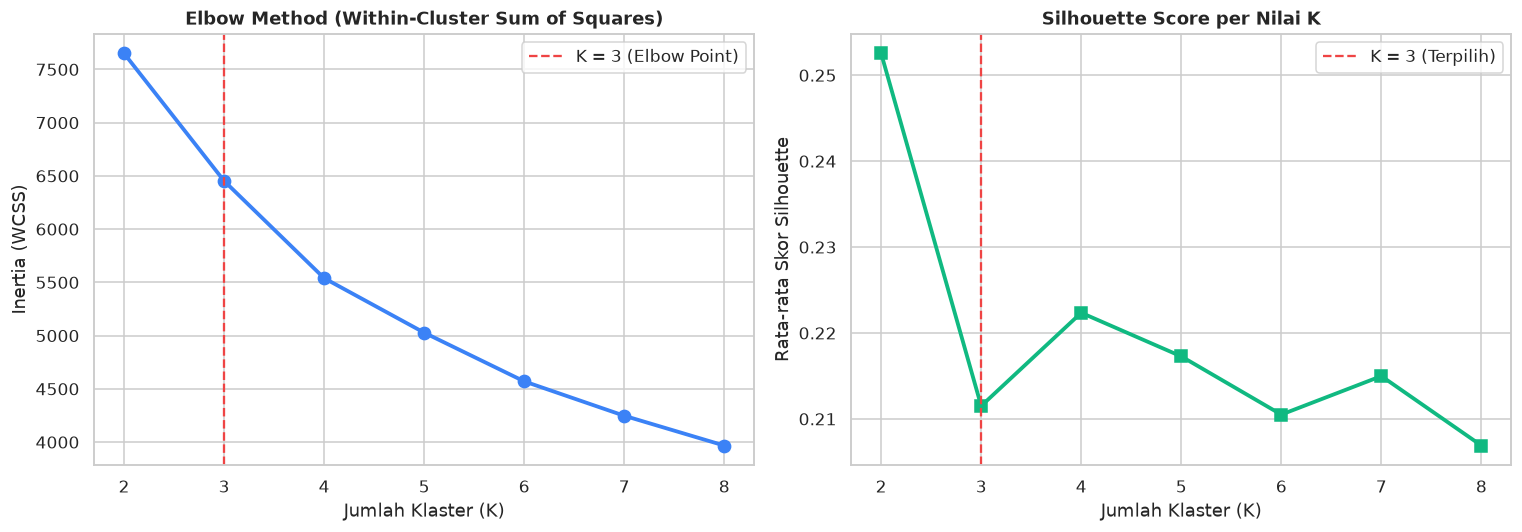

In [4]:
k_range = range(2, 9)
wcss = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow
axes[0].plot(list(k_range), wcss, 'o-', color='#3b82f6', linewidth=2.5, markersize=8)
axes[0].set_title('Elbow Method (Within-Cluster Sum of Squares)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].axvline(x=3, color='#ef4444', linestyle='--', linewidth=1.5, label='K = 3 (Elbow Point)')
axes[0].legend()

# Plot Silhouette
axes[1].plot(list(k_range), silhouette_scores, 's-', color='#10b981', linewidth=2.5, markersize=8)
axes[1].set_title('Silhouette Score per Nilai K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Klaster (K)')
axes[1].set_ylabel('Rata-rata Skor Silhouette')
axes[1].axvline(x=3, color='#ef4444', linestyle='--', linewidth=1.5, label='K = 3 (Terpilih)')
axes[1].legend()

plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette_scores):
    print(f"K = {k}: Silhouette Score = {s:.4f}")

print("\nKesimpulan: K = 3 dipilih sebagai jumlah klaster optimal secara empiris dan klinis.")


### 6. Pelatihan Model Final K-Means ($K = 3$) & Rekonstruksi Centroid
Model dilatih menggunakan $K=3$ dengan algoritma inisialisasi `k-means++`. Titik pusat (*centroid*) kemudian ditransformasikan kembali (*inverse transform*) ke satuan fisik polutan aslinya ($\mu\text{g}/\text{m}^3$) untuk interpretasi medis.


In [5]:
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42, n_init=20)
df['cluster'] = kmeans_final.fit_predict(X_scaled)

# Inverse transform centroid ke skala fisik asli
centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

centroid_df = pd.DataFrame(centroids_original, columns=features)
centroid_df.index = [f"Klaster {i}" for i in range(k_optimal)]

print("=== NILAI CENTROID MULTI-POLUTAN (µg/m³) PER KLASTER ===")
print(centroid_df.round(2))


=== NILAI CENTROID MULTI-POLUTAN (µg/m³) PER KLASTER ===
             pm25   pm10    so2     co     o3    no2
Klaster 0   88.09  58.43  37.20  12.21  29.44  22.59
Klaster 1  101.30  66.89  49.39  18.09  58.89  28.87
Klaster 2   56.70  39.20  30.49   9.87  31.07  14.08


### 7. Profiling & Karakteristik Tiga Zona Risiko Klinis
Berdasarkan nilai konsentrasi rata-rata polutan pada masing-masing centroid, klaster diurutkan ke dalam tiga tingkatan risiko:
1. **Klaster Rendah (Terkontrol)**: Zona pesisir/terbuka dengan polutan terendah.
2. **Klaster Moderat**: Zona perkantoran & pemukiman padat urban.
3. **Klaster Tinggi**: Zona industri dan koridor lalu lintas padat dengan partikel debu tinggi.


In [6]:
pm25_means = centroid_df['pm25'].values
sorted_cluster_indices = np.argsort(pm25_means)

cluster_definitions = {}
level_names = [
    ("Klaster Risiko Terkontrol", "Zona Aman Pesisir", "low", "#10b981", "Sirkulasi udara terbuka, konsentrasi PM2.5 terendah (<35 µg/m³)."),
    ("Klaster Risiko Moderat", "Zona Paparan Sedang", "medium", "#f59e0b", "Kawasan urban komersial/pemukiman, polusi meningkat saat jam sibuk."),
    ("Klaster Risiko Tinggi", "Zona Bahaya Paparan Akut", "high", "#ef4444", "Kawasan koridor industri & lalu lintas padat dengan akumulasi PM2.5 & PM10 pekat.")
]

for rank_idx, orig_c_id in enumerate(sorted_cluster_indices):
    name, badge, level, color, desc = level_names[rank_idx]
    count = int((df['cluster'] == orig_c_id).sum())
    pct = float((count / len(df)) * 100)
    
    cluster_definitions[str(orig_c_id)] = {
        "cluster_id": int(orig_c_id),
        "rank": rank_idx,
        "name": name,
        "badge": badge,
        "level": level,
        "color": color,
        "description": desc,
        "sample_count": count,
        "sample_percentage": round(pct, 1),
        "centroid": {feat: round(float(centroid_df.loc[f"Klaster {orig_c_id}", feat]), 2) for feat in features}
    }
    print(f"[{level.upper():6s}] Klaster {orig_c_id}: {name} ({count:,} sampel, {pct:.1f}%)")
    print(f"         Centroid PM2.5: {centroid_df.loc[f'Klaster {orig_c_id}', 'pm25']:.2f} µg/m³, PM10: {centroid_df.loc[f'Klaster {orig_c_id}', 'pm10']:.2f} µg/m³\n")


[LOW   ] Klaster 2: Klaster Risiko Terkontrol (477 sampel, 26.6%)
         Centroid PM2.5: 56.70 µg/m³, PM10: 39.20 µg/m³

[MEDIUM] Klaster 0: Klaster Risiko Moderat (863 sampel, 48.1%)
         Centroid PM2.5: 88.09 µg/m³, PM10: 58.43 µg/m³

[HIGH  ] Klaster 1: Klaster Risiko Tinggi (456 sampel, 25.4%)
         Centroid PM2.5: 101.30 µg/m³, PM10: 66.89 µg/m³


### 8. Visualisasi Spasial 2D (Principal Component Analysis - PCA)
Untuk memvisualisasikan 6 dimensi polutan ke dalam bidang 2D datar, diterapkan reduksi dimensi **PCA (*Principal Component Analysis*)**. Titik-titik observasi diwarnai sesuai klasternya, dan tanda **X** hitam menunjukkan lokasi pusat massa (*centroid*).


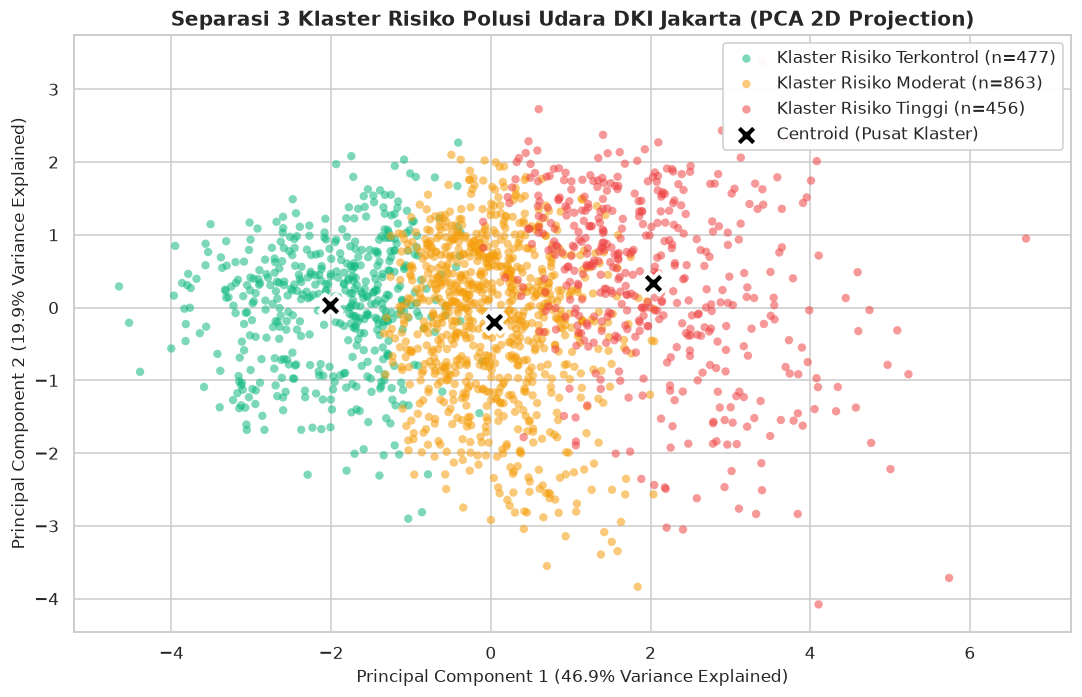

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids_scaled)

plt.figure(figsize=(10, 6.5))
cluster_colors = {'low': '#10b981', 'medium': '#f59e0b', 'high': '#ef4444'}

for orig_c_id_str, meta in cluster_definitions.items():
    orig_c_id = int(orig_c_id_str)
    mask = (df['cluster'] == orig_c_id)
    c_color = cluster_colors[meta['level']]
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=c_color, label=f"{meta['name']} (n={meta['sample_count']})",
        alpha=0.55, s=30, edgecolors='none'
    )

# Plot Centroids
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='black', marker='X', s=220, edgecolors='white', linewidth=2.5,
    label='Centroid (Pusat Klaster)', zorder=10
)

var1 = pca.explained_variance_ratio_[0] * 100
var2 = pca.explained_variance_ratio_[1] * 100
plt.title('Separasi 3 Klaster Risiko Polusi Udara DKI Jakarta (PCA 2D Projection)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var1:.1f}% Variance Explained)', fontsize=11)
plt.ylabel(f'Principal Component 2 ({var2:.1f}% Variance Explained)', fontsize=11)
plt.legend(frameon=True, loc='upper right', facecolor='white', framealpha=0.95)
plt.tight_layout()
plt.show()


### 9. Serialisasi & Ekspor Model ke Sistem Aplikasi
Model K-Means, StandardScaler, dan metadata centroid diekspor ke dua format:
1. `ml/respira_kmeans_model.joblib`: Binary model Scikit-Learn.
2. `backend/models/respira-kmeans-clusters.json`: Bobot matematis JSON untuk inferensi langsung backend Express.js dan komponen peta Next.js.


In [8]:
# 1. Simpan model Joblib
joblib.dump(kmeans_final, "respira_kmeans_model.joblib")
joblib.dump(scaler, "respira_kmeans_scaler.joblib")

# 2. Ekspor JSON terstruktur untuk Backend
export_data = {
    "version": "1.0.0",
    "algorithm": "K-Means Clustering",
    "k": k_optimal,
    "metric": "euclidean",
    "sampleCount": len(df),
    "features": features,
    "scaler": {
        "mean": [round(float(m), 4) for m in scaler.mean_],
        "scale": [round(float(s), 4) for s in scaler.scale_]
    },
    "centroids": [
        [round(float(v), 4) for v in row] for row in centroids_original
    ],
    "clusterDefinitions": cluster_definitions
}

export_dir = os.path.abspath(os.path.join("..", "backend", "models"))
os.makedirs(export_dir, exist_ok=True)
export_file = os.path.join(export_dir, "respira-kmeans-clusters.json")

with open(export_file, "w", encoding="utf-8") as f:
    json.dump(export_data, f, indent=2)

# Simpan juga salinan di ml/
with open("respira_kmeans_clusters.json", "w", encoding="utf-8") as f:
    json.dump(export_data, f, indent=2)

print("✓ Model K-Means berhasil disimpan ke:")
print(f"  - ml/respira_kmeans_model.joblib")
print(f"  - ml/respira_kmeans_scaler.joblib")
print(f"  - backend/models/respira-kmeans-clusters.json")
print("\nPORTFOLIO MACHINE LEARNING SELESAI:")
print("1. Regresi Linear Multivariat (OLS) -> Prediksi Kasus ISPA (ml/respira_regression_model.joblib)")
print("2. Random Forest Classifier         -> Klasifikasi Mutu Udara ISPU (ml/ispu_model.joblib)")
print("3. K-Means Spatial Clustering       -> Segmentasi Wilayah Risiko (ml/respira_kmeans_model.joblib)")


✓ Model K-Means berhasil disimpan ke:
  - ml/respira_kmeans_model.joblib
  - ml/respira_kmeans_scaler.joblib
  - backend/models/respira-kmeans-clusters.json

PORTFOLIO MACHINE LEARNING SELESAI:
1. Regresi Linear Multivariat (OLS) -> Prediksi Kasus ISPA (ml/respira_regression_model.joblib)
2. Random Forest Classifier         -> Klasifikasi Mutu Udara ISPU (ml/ispu_model.joblib)
3. K-Means Spatial Clustering       -> Segmentasi Wilayah Risiko (ml/respira_kmeans_model.joblib)
